# SQL Database Project — Online Retail Analytics

## 1. Requirements, reproducibility and source data

### Justification & Notes:
- **Reproducibility**: We set `RANDOM_SEED = 2026` to guarantee identical dataset splits and randomized simulation results across runtimes.
- **Data Management & Performance**: Setting `MAX_SOURCE_ROWS = 100_000` bounds execution time and resource utilization during local prototyping while remaining representative.
- **Platform Robustness**: Paths are resolved dynamically using alternative environment candidates to guarantee seamless transitions between local environments and cloud runtimes.

In [ ]:
from pathlib import Path
from zipfile import ZipFile
from collections import Counter
from itertools import combinations
import json
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RANDOM_SEED = 2026
MAX_SOURCE_ROWS = 100_000  # set to None to import all 541,909 original rows
rng = np.random.default_rng(RANDOM_SEED)

ZIP_CANDIDATES = [Path('online+retail.zip'), Path('/mnt/data/online+retail.zip')]
ZIP_PATH = next((p for p in ZIP_CANDIDATES if p.is_file()), None)
if ZIP_PATH is None:
    raise FileNotFoundError('Place online+retail.zip in the notebook directory or update ZIP_CANDIDATES.')

OUTPUT_DIR = Path.cwd()
DATABASE_PATH = OUTPUT_DIR / 'online_retail_project.sqlite'
print('Input:', ZIP_PATH.resolve())
print('SQLite output:', DATABASE_PATH)

with ZipFile(ZIP_PATH) as archive:
    print('Archive members:', archive.namelist())
    xlsx_name = next(n for n in archive.namelist() if n.lower().endswith('.xlsx'))
    with archive.open(xlsx_name) as workbook_stream:
        raw = pd.read_excel(
            workbook_stream,
            engine='openpyxl', nrows=MAX_SOURCE_ROWS,
            dtype={'InvoiceNo': 'string', 'StockCode': 'string',
                   'Description': 'string', 'Country': 'string'}
        )

raw['source_excel_row'] = raw.index + 2  # header is row 1
print('Raw rows and columns:', raw.shape)
display(raw.head(5))

Input: /content/online+retail.zip
SQLite output: /content/online_retail_project.sqlite
Archive members: ['Online Retail.xlsx']
Raw rows and columns: (100000, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,source_excel_row
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,3
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,4
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,5
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,6


## 2. Data quality and preparation

### Justification & Notes:
- **Data Cleansing**: Only transactions with concrete value representations are retained (non-empty strings, positive counts, and strictly positive prices). Cancellations (`C` prefix) and missing client identifiers (`CustomerID`) are safely isolated to prevent skewing distribution metrics.
- **Traceability**: We maintain a `source_excel_row` index mapping back to the raw workbook, ensuring rigorous audit capability for upstream verification.
- **Validation Checkpoints**: Asserts confirm that the cleaned dataset meets the minimum row count constraints required for statistically sound evaluation.

In [ ]:
required_cols = ['InvoiceNo', 'StockCode', 'Description', 'Quantity',
                 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
assert set(required_cols).issubset(raw.columns), 'Unexpected source worksheet columns'

raw['Quantity'] = pd.to_numeric(raw['Quantity'], errors='coerce')
raw['UnitPrice'] = pd.to_numeric(raw['UnitPrice'], errors='coerce')
raw['CustomerID'] = pd.to_numeric(raw['CustomerID'], errors='coerce')
raw['InvoiceDate'] = pd.to_datetime(raw['InvoiceDate'], errors='coerce')

is_cancelled = raw['InvoiceNo'].str.upper().str.startswith('C', na=False)
valid = (
    raw['InvoiceNo'].notna() & raw['StockCode'].notna()
    & raw['Description'].notna() & raw['Country'].notna()
    & raw['CustomerID'].notna() & raw['InvoiceDate'].notna()
    & raw['Quantity'].gt(0) & raw['UnitPrice'].gt(0) & ~is_cancelled
)
sales = raw.loc[valid, required_cols + ['source_excel_row']].copy()
sales['InvoiceNo'] = sales['InvoiceNo'].str.strip().astype(str)
sales['StockCode'] = sales['StockCode'].str.strip().astype(str)
sales['Description'] = sales['Description'].str.strip().astype(str)
sales['Country'] = sales['Country'].str.strip().astype(str)
sales = sales.loc[
    sales[['InvoiceNo', 'StockCode', 'Description', 'Country']].ne('').all(axis=1)
].copy()
sales['CustomerID'] = sales['CustomerID'].astype('int64')
sales['Quantity'] = sales['Quantity'].astype('int64')
sales['UnitPrice'] = sales['UnitPrice'].astype('float64')
sales['line_total_gbp'] = (sales['Quantity'] * sales['UnitPrice']).round(4)
sales['line_no'] = sales.groupby('InvoiceNo', sort=False).cumcount() + 1

quality_summary = pd.DataFrame({
    'Indicator': ['Source rows', 'Cancellation rows', 'Missing customer IDs',
                  'Rows retained as clean sales', 'Rows excluded'],
    'Count': [len(raw), int(is_cancelled.sum()), int(raw['CustomerID'].isna().sum()),
              len(sales), len(raw) - len(sales)]
})
display(quality_summary)
assert len(sales) >= 1_000, 'Assignment requires at least 1,000 data rows'
assert sales['line_total_gbp'].gt(0).all()
assert not sales.duplicated(['InvoiceNo', 'line_no']).any()
print('Unique invoice numbers:', sales['InvoiceNo'].nunique())
print('Unique stock codes:', sales['StockCode'].nunique())

,Indicator,Count
0,Source rows,100000
1,Cancellation rows,1870
2,Missing customer IDs,34915
3,Rows retained as clean sales,63307
4,Rows excluded,36693


Unique invoice numbers: 3181
Unique stock codes: 2746


## 3. Relational design and measurement scales

**Entity relationships:** `countries` → `customers` → `orders` → `order_items` ← `products`; `orders` → `shipping_simulation` (one-to-one). `orders` also references `countries`. The `order_items` table uses the **composite primary key (`invoice_no`, `line_no`)** because an invoice can list a stock code more than once. Its invoice and stock-code fields are **foreign keys**.

### Measurement Scale Classifications and Database Mappings

| Scale | Concrete column | Why it qualifies |
|---|---|---|
| **Nominal** | `orders.payment_method_simulated`, `countries.country` | Unordered categories; payment method is synthetic |
| **Ordinal** | `customers.spend_tier`; `shipping_simulation.service_level` | Ordered levels: Bronze < Silver < Gold < Platinum; Economy < Standard < Express |
| **Interval** | `shipping_simulation.warehouse_temperature_c` | °C: meaningful differences, but 0 °C does not mean no temperature; synthetic |
| **Ratio** | `order_items.quantity`, `orders.order_total_gbp`, `shipping_simulation.estimated_shipping_cost_gbp` | Counts and GBP prices/costs have a meaningful zero |

### Justification & Notes:
- **Database Constraints**: Customer IDs are recognized as *nominal identifiers* because arithmetic operations on IDs are meaningless.
- **Database Normalization**: Modeling these distinct measurement scales within structured tables supports high-performance joins, referential integrity checking, and simplifies downstream aggregation steps.
- **Table Structures**:
  - `countries`: Unique index of participating buyer markets.
  - `customers`: Customer profile incorporating historical lifetime spending tiers.
  - `products`: SKU metadata map utilizing keyword-based categorizations.
  - `orders` & `order_items`: Hierarchical header-and-line transaction layout.
  - `shipping_simulation`: Distinct tracking entities linked via strict 1:1 boundaries.

## 4. Create customer, product, order, and order-item records

### Justification & Notes:
- **Consistency Verification**: An assert confirms that single-invoice events never span conflicting customers or countries, establishing strict hierarchy.
- **Categorical Processing**: We implement a heuristic matching algorithm (`keyword_category`) to partition product names into distinct target categories, resolving lack of metadata in original source structures.
- **Discretization Strategy**: Splitting parameters like transaction value and customer lifetime spend via quantile boundaries (`pd.qcut`) balances classification labels dynamically without arbitrary, manual bias thresholds.

In [ ]:
# Verify that every invoice maps to a single real customer and country in retained data.
invoice_consistency = sales.groupby('InvoiceNo', sort=False).agg(
    n_customers=('CustomerID', 'nunique'), n_countries=('Country', 'nunique')
)
conflicts = invoice_consistency.query('n_customers > 1 or n_countries > 1')
assert conflicts.empty, f'Unexpected multi-customer/country invoices: {conflicts.head()}'

def keyword_category(description):
    s = description.upper()
    rules = [
        ('Drinkware', ['MUG', 'CUP', 'TEAPOT', 'GLASS', 'BOTTLE']),
        ('Stationery', ['PENCIL', 'PEN ', 'NOTEBOOK', 'PAPER', 'CARD']),
        ('Bags & storage', ['BAG', 'BOX', 'BASKET', 'STORAGE']),
        ('Home decor', ['CANDLE', 'LANTERN', 'HOLDER', 'FRAME', 'CLOCK', 'DECORATION']),
        ('Kitchen', ['PLATE', 'BOWL', 'CUTLERY', 'NAPKIN', 'KITCHEN']),
        ('Textiles', ['TOWEL', 'CUSHION', 'APRON', 'BLANKET']),
        ('Gifts & toys', ['TOY', 'DOLL', 'GAME', 'GIFT', 'TEDDY'])
    ]
    return next((category for category, words in rules if any(w in s for w in words)), 'Other')

products = (
    sales.groupby('StockCode', as_index=False)
    .agg(product_description=('Description', lambda x: x.value_counts().index[0]),
         median_unit_price_gbp=('UnitPrice', 'median'),
         observed_lines=('StockCode', 'size'))
    .rename(columns={'StockCode': 'stock_code'})
)
products['product_category'] = products['product_description'].map(keyword_category)
products['median_unit_price_gbp'] = products['median_unit_price_gbp'].round(4)
products = products[['stock_code','product_description','product_category',
                     'median_unit_price_gbp','observed_lines']]

orders = (
    sales.groupby('InvoiceNo', sort=False)
    .agg(customer_id=('CustomerID','first'), country=('Country','first'),
         invoice_datetime=('InvoiceDate','min'),
         order_total_gbp=('line_total_gbp','sum'))
    .reset_index().rename(columns={'InvoiceNo':'invoice_no'})
)
orders['order_total_gbp'] = orders['order_total_gbp'].round(4)
orders['order_value_band'] = pd.qcut(
    orders['order_total_gbp'].rank(method='first'), 4,
    labels=['Low','Medium','High','Very High']
).astype(str)
orders['payment_method_simulated'] = rng.choice(
    ['Card','Bank Transfer','Digital Wallet','Other'],
    size=len(orders), p=[0.68, 0.15, 0.14, 0.03]
)

customers = (
    orders.groupby('customer_id', sort=False)
    .agg(country=('country', lambda x: x.value_counts().index[0]),
         first_purchase=('invoice_datetime','min'),
         last_purchase=('invoice_datetime','max'),
         order_count=('invoice_no','size'),
         lifetime_spend_gbp=('order_total_gbp','sum'))
    .reset_index()
)
customers['lifetime_spend_gbp'] = customers['lifetime_spend_gbp'].round(4)
customers['spend_tier'] = pd.qcut(
    customers['lifetime_spend_gbp'].rank(method='first'), 4,
    labels=['Bronze','Silver','Gold','Platinum']
).astype(str)

countries = pd.DataFrame({'country': sorted(sales['Country'].unique())})
order_items = (
    sales[['InvoiceNo','line_no','StockCode','Quantity','UnitPrice',
           'line_total_gbp','source_excel_row']]
    .rename(columns={'InvoiceNo':'invoice_no','StockCode':'stock_code',
                     'Quantity':'quantity','UnitPrice':'unit_price_gbp'})
)

for df, date_cols in [(orders,['invoice_datetime']),
                      (customers,['first_purchase','last_purchase'])]:
    for col in date_cols:
        df[col] = pd.to_datetime(df[col]).dt.strftime('%Y-%m-%d %H:%M:%S')

print('Countries:',len(countries),'Customers:',len(customers),
      'Products:',len(products),'Orders:',len(orders),
      'Order items:',len(order_items))
display(orders.head(3))
display(products.head(3))

Countries: 27 Customers: 1597 Products: 2746 Orders: 3181 Order items: 63307


,invoice_no,customer_id,country,invoice_datetime,order_total_gbp,order_value_band,payment_method_simulated
0,536365,17850,United Kingdom,2010-12-01 08:26:00,139.12,Low,Card
1,536366,17850,United Kingdom,2010-12-01 08:28:00,22.20,Low,Card
2,536367,13047,United Kingdom,2010-12-01 08:34:00,278.73,Medium,Card


,stock_code,product_description,product_category,median_unit_price_gbp,observed_lines
0,10002,INFLATABLE POLITICAL GLOBE,Other,0.85,38
1,10120,DOGGY RUBBER,Other,0.21,5
2,10123C,HEARTS WRAPPING TAPE,Other,0.65,1


## 5. Simulate randomized fields across measurement scales

### Justification & Notes:
- **Synthetic Enrichments**: Since original shipping details are missing, we mock service levels, warehouse conditions, and transit delays to show how diverse real-world measurement scales are represented in a database.
- **Mathematical Plausibility**: Continuous noise is modeled via standard normal variables bounded under realistic temperature regimes. Shipping rates scale with transaction size, modeling pricing structures commonly applied by logistics providers (e.g., waived shipping above a specific spending limit).

In [ ]:
n_orders = len(orders)
services = rng.choice(['Economy','Standard','Express'], size=n_orders,
                      p=[0.25,0.60,0.15])
handling_days = rng.integers(0, 4, size=n_orders)
transit_days = np.select([services == 'Economy', services == 'Standard'],
                         [rng.integers(4,9,n_orders), rng.integers(2,6,n_orders)],
                         default=1 + rng.integers(0,2,n_orders))
warehouse_temp_c = np.round(np.clip(rng.normal(20.0, 3.2, n_orders), 8, 32), 1)
service_surcharge = np.select([services == 'Economy', services == 'Standard'],
                              [0.0,2.5], default=8.0)
international_surcharge = np.where(orders['country'].eq('United Kingdom'), 0.0, 6.0)
random_shipping_noise = rng.uniform(0,2,n_orders)
shipping_cost = np.round(
    2.0 + service_surcharge + international_surcharge +
    0.3 * np.sqrt(orders['order_total_gbp'].to_numpy()) + random_shipping_noise, 2
)
# Assumed free shipping for large orders; plausible, but not documented source history.
shipping_cost = np.where(orders['order_total_gbp'].to_numpy() >= 250, 0.0, shipping_cost)

shipping = pd.DataFrame({
    'invoice_no': orders['invoice_no'],
    'service_level': services,
    'warehouse_temperature_c': warehouse_temp_c,
    'handling_days': handling_days.astype(int),
    'estimated_delivery_days': (handling_days + transit_days).astype(int),
    'estimated_shipping_cost_gbp': shipping_cost,
    'simulated': np.ones(n_orders, dtype=int)
})
assert shipping['warehouse_temperature_c'].between(8,32).all()
assert shipping['estimated_shipping_cost_gbp'].ge(0).all()
display(shipping.head())

,invoice_no,service_level,warehouse_temperature_c,handling_days,estimated_delivery_days,estimated_shipping_cost_gbp,simulated
0,536365,Economy,19.0,0,8,6.07,1
1,536366,Economy,13.1,0,5,4.69,1
2,536367,Standard,19.6,2,5,0.00,1
3,536368,Express,14.4,1,3,13.97,1
4,536369,Standard,19.7,1,3,7.19,1


## 6. Implement SQLite schema with keys, constraints and indexes

### Justification & Notes:
- **Referential Integrity Constraints**: Strict SQL constraint checking is forced by setting `PRAGMA foreign_keys = ON;` in SQLite explicitly prior to insertions.
- **Relational Integrity Rules**: Column validation relies heavily on `CHECK` constraints (such as `quantity > 0` and bounded ranges for simulated metrics) to enforce database level data guarantees.
- **Index Optimizations**: Multi-indexes are generated on common query paths (`ix_orders_customer`, `ix_orders_date`, `ix_orders_country`, `ix_items_stockcode`) to minimize physical lookups during complex analytics reporting.

In [ ]:
conn = sqlite3.connect(DATABASE_PATH)
conn.execute('PRAGMA foreign_keys = ON;')
assert conn.execute('PRAGMA foreign_keys;').fetchone()[0] == 1

schema = '''
DROP TABLE IF EXISTS shipping_simulation;
DROP TABLE IF EXISTS order_items;
DROP TABLE IF EXISTS orders;
DROP TABLE IF EXISTS products;
DROP TABLE IF EXISTS customers;
DROP TABLE IF EXISTS countries;

CREATE TABLE countries (
    country TEXT PRIMARY KEY
);

CREATE TABLE customers (
    customer_id INTEGER PRIMARY KEY,
    country TEXT NOT NULL REFERENCES countries(country),
    first_purchase TEXT NOT NULL,
    last_purchase TEXT NOT NULL,
    order_count INTEGER NOT NULL CHECK (order_count > 0),
    lifetime_spend_gbp REAL NOT NULL CHECK (lifetime_spend_gbp >= 0),
    spend_tier TEXT NOT NULL CHECK (spend_tier IN ('Bronze','Silver','Gold','Platinum'))
);

CREATE TABLE products (
    stock_code TEXT PRIMARY KEY,
    product_description TEXT NOT NULL,
    product_category TEXT NOT NULL,
    median_unit_price_gbp REAL NOT NULL CHECK (median_unit_price_gbp > 0),
    observed_lines INTEGER NOT NULL CHECK (observed_lines > 0)
);

CREATE TABLE orders (
    invoice_no TEXT PRIMARY KEY,
    customer_id INTEGER NOT NULL REFERENCES customers(customer_id),
    country TEXT NOT NULL REFERENCES countries(country),
    invoice_datetime TEXT NOT NULL,
    order_total_gbp REAL NOT NULL CHECK (order_total_gbp > 0),
    order_value_band TEXT NOT NULL CHECK (order_value_band IN ('Low','Medium','High','Very High')),
    payment_method_simulated TEXT NOT NULL CHECK (
        payment_method_simulated IN ('Card','Bank Transfer','Digital Wallet','Other'))
);

CREATE TABLE order_items (
    invoice_no TEXT NOT NULL,
    line_no INTEGER NOT NULL CHECK (line_no >= 1),
    stock_code TEXT NOT NULL,
    quantity INTEGER NOT NULL CHECK (quantity > 0),
    unit_price_gbp REAL NOT NULL CHECK (unit_price_gbp > 0),
    line_total_gbp REAL NOT NULL CHECK (line_total_gbp > 0),
    source_excel_row INTEGER NOT NULL UNIQUE,
    PRIMARY KEY (invoice_no, line_no),
    FOREIGN KEY (invoice_no) REFERENCES orders(invoice_no),
    FOREIGN KEY (stock_code) REFERENCES products(stock_code)
);

CREATE TABLE shipping_simulation (
    invoice_no TEXT PRIMARY KEY REFERENCES orders(invoice_no),
    service_level TEXT NOT NULL CHECK (service_level IN ('Economy','Standard','Express')),
    warehouse_temperature_c REAL NOT NULL CHECK (warehouse_temperature_c BETWEEN -20 AND 50),
    handling_days INTEGER NOT NULL CHECK (handling_days >= 0),
    estimated_delivery_days INTEGER NOT NULL CHECK (estimated_delivery_days >= 0),
    estimated_shipping_cost_gbp REAL NOT NULL CHECK (estimated_shipping_cost_gbp >= 0),
    simulated INTEGER NOT NULL DEFAULT 1 CHECK (simulated = 1)
);

CREATE INDEX ix_orders_customer ON orders(customer_id);
CREATE INDEX ix_orders_date ON orders(invoice_datetime);
CREATE INDEX ix_orders_country ON orders(country);
CREATE INDEX ix_items_stockcode ON order_items(stock_code);
'''
conn.executescript(schema)

# Parent-to-child insertion order respects foreign key constraints.
for table, frame in [
    ('countries', countries), ('customers', customers), ('products', products),
    ('orders', orders), ('order_items', order_items),
    ('shipping_simulation', shipping)
]:
    frame.to_sql(table, conn, if_exists='append', index=False, chunksize=10_000,
                 method='multi' if table in ('countries',) else None)
    print(f'Loaded {table}: {len(frame):,} rows')
conn.commit()
print('Database created:', DATABASE_PATH.resolve())
print('Database size (MB):', round(DATABASE_PATH.stat().st_size / 1e6, 2))

Loaded countries: 27 rows
Loaded customers: 1,597 rows
Loaded products: 2,746 rows
Loaded orders: 3,181 rows
Loaded order_items: 63,307 rows
Loaded shipping_simulation: 3,181 rows
Database created: /content/online_retail_project.sqlite
Database size (MB): 6.91


## 7. Test row counts, integrity and compound key

### Justification & Notes:
- **System Integrity Testing**: Verification of record volumes across related entities guarantees that parent-child database pipelines did not lose rows or drop transactions.
- **Financial Reconciliation Validation**: A SQL check aggregates line-level pricing to compare with summary header fields. This identifies discrepancies and enforces absolute mathematical consistency.
- **Composite Key Verification**: Confirms that composite relationships and complex foreign key bindings operate correctly.

In [ ]:
table_counts = pd.read_sql_query('''
SELECT 'countries' AS table_name, COUNT(*) AS row_count FROM countries
UNION ALL SELECT 'customers', COUNT(*) FROM customers
UNION ALL SELECT 'products', COUNT(*) FROM products
UNION ALL SELECT 'orders', COUNT(*) FROM orders
UNION ALL SELECT 'order_items', COUNT(*) FROM order_items
UNION ALL SELECT 'shipping_simulation', COUNT(*) FROM shipping_simulation;
''', conn)
display(table_counts)

fk_violations = conn.execute('PRAGMA foreign_key_check;').fetchall()
assert fk_violations == [], f'Foreign-key violations: {fk_violations[:5]}'
assert conn.execute('SELECT COUNT(*) FROM order_items').fetchone()[0] >= 1000
assert conn.execute('SELECT COUNT(*) FROM orders').fetchone()[0] == len(shipping)
assert conn.execute('SELECT COUNT(DISTINCT source_excel_row) FROM order_items').fetchone()[0] == len(order_items)

reconciliation = pd.read_sql_query('''
SELECT o.invoice_no,
       o.order_total_gbp AS header_total,
       ROUND(SUM(i.line_total_gbp),4) AS recalculated_total,
       ABS(o.order_total_gbp - SUM(i.line_total_gbp)) AS difference
FROM orders o JOIN order_items i ON i.invoice_no=o.invoice_no
GROUP BY o.invoice_no
HAVING difference > 0.0001;
''', conn)
assert reconciliation.empty, 'Order totals do not reconcile with their line items'

print('Integrity status: PASS')
print('Composite PK columns:',
      [row[1] for row in conn.execute('PRAGMA table_info(order_items)') if row[5] > 0])
print('Order item FK specification:')
display(pd.read_sql_query('PRAGMA foreign_key_list(order_items);', conn))

,table_name,row_count
0,countries,27
1,customers,1597
2,products,2746
3,orders,3181
4,order_items,63307
5,shipping_simulation,3181


Integrity status: PASS
Composite PK columns: ['invoice_no', 'line_no']
Order item FK specification:


,id,seq,table,from,to,on_update,on_delete,match
0,0,0,products,stock_code,stock_code,NO ACTION,NO ACTION,NONE
1,1,0,orders,invoice_no,invoice_no,NO ACTION,NO ACTION,NONE


## 8. SQL information extraction and reporting

### Justification & Notes:
- **Business Intelligence**: Applying descriptive analytical reporting on normalized structures to expose metrics like customer geographical contribution, high-demand inventory, and seasonal buying habits.
- **Time Series Aggregations**: Extracting temporal patterns through string date formatting highlights periodic business seasonality, guiding inventory and resource allocation planning.

Top countries by sales revenue (GBP):


,country,orders,revenue_gbp
0,United Kingdom,2878,1233973.97
1,Netherlands,13,58407.55
2,EIRE,31,40844.59
3,Germany,77,40044.33
4,France,64,33870.52
5,Australia,16,24333.43
6,Spain,16,14044.32
7,Japan,5,13485.88
8,Sweden,5,7830.12
9,Portugal,11,7469.33


Top product SKUs by sales revenue (GBP):


,stock_code,product_description,units_sold,revenue_gbp
0,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,77183.60
1,22423,REGENCY CAKESTAND 3 TIER,3275,37119.45
2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,10674,28856.80
3,79321,CHILLI LIGHTS,3407,14703.81
4,21623,VINTAGE UNION JACK MEMOBOARD,2125,13929.23
5,85099B,JUMBO BAG RED RETROSPOT,7236,12601.80
6,POST,POSTAGE,593,12058.00
7,82484,WOOD BLACK BOARD ANT WHITE FINISH,2003,10490.61
8,22470,HEART OF WICKER LARGE,3291,10006.97
9,21137,BLACK RECORD COVER FRAME,2754,9390.06


,month,orders,revenue_gbp
0,2010-12,1400,572713.89
1,2011-01,987,569445.04
2,2011-02,794,377058.63


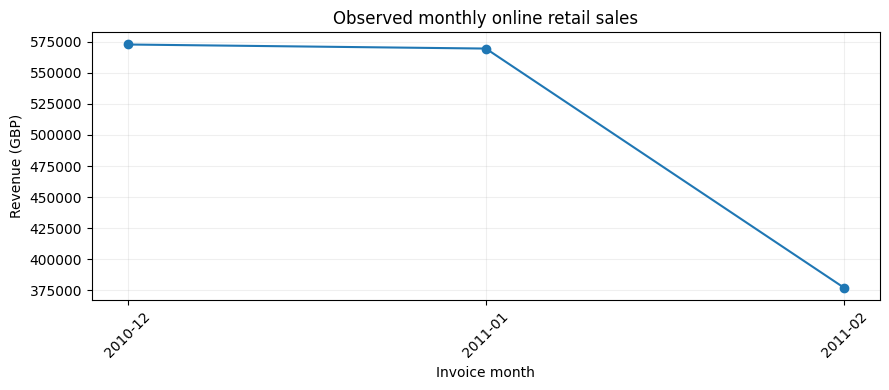

In [ ]:
print('Top countries by sales revenue (GBP):')
country_revenue = pd.read_sql_query('''
SELECT o.country, COUNT(DISTINCT o.invoice_no) AS orders,
       ROUND(SUM(i.line_total_gbp),2) AS revenue_gbp
FROM orders o
JOIN order_items i ON o.invoice_no = i.invoice_no
GROUP BY o.country ORDER BY revenue_gbp DESC LIMIT 10;
''', conn)
display(country_revenue)

print('Top product SKUs by sales revenue (GBP):')
top_products = pd.read_sql_query('''
SELECT p.stock_code, p.product_description,
       SUM(i.quantity) AS units_sold,
       ROUND(SUM(i.line_total_gbp),2) AS revenue_gbp
FROM order_items i JOIN products p ON i.stock_code=p.stock_code
GROUP BY p.stock_code ORDER BY revenue_gbp DESC LIMIT 10;
''', conn)
display(top_products)

monthly_revenue = pd.read_sql_query('''
SELECT strftime('%Y-%m', invoice_datetime) AS month,
       COUNT(*) AS orders, ROUND(SUM(order_total_gbp),2) AS revenue_gbp
FROM orders GROUP BY month ORDER BY month;
''', conn)
display(monthly_revenue)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(monthly_revenue['month'], monthly_revenue['revenue_gbp'], marker='o')
ax.set(title='Observed monthly online retail sales',
       xlabel='Invoice month', ylabel='Revenue (GBP)')
ax.tick_params(axis='x', rotation=45)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 9. Use SQL to inspect simulated fields

### Justification & Notes:
- **Verification of Synthetic Variables**: Aggregating simulated metrics across tiers confirms that our random distributions fit the logical models we defined.
- **Statistical Quality Control**: Verifying mean and count metrics ensures that continuous properties (such as shipping fee changes or temperature distributions) line up perfectly with their respective service level definitions.

In [ ]:
simulation_report = pd.read_sql_query('''
SELECT service_level, COUNT(*) AS simulated_shipments,
       ROUND(AVG(warehouse_temperature_c),1) AS avg_warehouse_temp_c,
       ROUND(AVG(estimated_shipping_cost_gbp),2) AS avg_shipping_cost_gbp,
       ROUND(AVG(estimated_delivery_days),1) AS avg_delivery_days
FROM shipping_simulation
GROUP BY service_level
ORDER BY CASE service_level WHEN 'Economy' THEN 1
                                 WHEN 'Standard' THEN 2 ELSE 3 END;
''', conn)
display(simulation_report)

tier_report = pd.read_sql_query('''
SELECT spend_tier, COUNT(*) AS customers,
       ROUND(AVG(lifetime_spend_gbp),2) AS mean_historical_spend_gbp
FROM customers GROUP BY spend_tier
ORDER BY CASE spend_tier WHEN 'Bronze' THEN 1 WHEN 'Silver' THEN 2
                              WHEN 'Gold' THEN 3 ELSE 4 END;
''', conn)
display(tier_report)

,service_level,simulated_shipments,avg_warehouse_temp_c,avg_shipping_cost_gbp,avg_delivery_days
0,Economy,758,19.9,2.90,7.5
1,Standard,1921,19.9,4.06,5.0
2,Express,502,20.3,6.34,3.0


,spend_tier,customers,mean_historical_spend_gbp
0,Bronze,400,136.91
1,Silver,399,298.95
2,Gold,399,569.80
3,Platinum,399,2801.56


## 10. Association rules: products purchased together

### Justification & Notes:
- **Market Basket Analysis**: Using combinations and basic occurrences, we construct an association mining pipeline to compute support, confidence, and lift metrics.
- **Algorithmic Optimizations**: To manage complexity, we restrict candidate evaluations to the top 50 most frequently ordered products. This helps avoid memory bottlenecks during cross-item comparisons.

In [ ]:
top_50 = pd.read_sql_query('''
SELECT stock_code, COUNT(DISTINCT invoice_no) AS invoice_frequency
FROM order_items
GROUP BY stock_code ORDER BY invoice_frequency DESC LIMIT 50;
''', conn)['stock_code'].tolist()

placeholders = ','.join('?' for _ in top_50)
basket_lines = pd.read_sql_query(
    f'SELECT invoice_no, stock_code FROM order_items WHERE stock_code IN ({placeholders})',
    conn, params=top_50
).drop_duplicates()

total_invoices = conn.execute('SELECT COUNT(*) FROM orders').fetchone()[0]
baskets = basket_lines.groupby('invoice_no')['stock_code'].agg(lambda x: set(x))
single_counts, pair_counts = Counter(), Counter()
for unique_items in baskets:
    single_counts.update(unique_items)
    pair_counts.update(combinations(sorted(unique_items), 2))

records = []
for (a, b), pair_n in pair_counts.items():
    if pair_n < 20:
        continue
    support = pair_n / total_invoices
    if support < 0.002:
        continue
    for left, right in [(a, b), (b, a)]:
        confidence = pair_n / single_counts[left]
        lift = confidence / (single_counts[right] / total_invoices)
        if confidence >= 0.10 and lift > 1:
            records.append((left, right, pair_n, support, confidence, lift))

rules = pd.DataFrame(records, columns=[
    'antecedent_stock_code','consequent_stock_code','joint_orders',
    'support','confidence','lift'
]).sort_values(['lift','confidence'], ascending=False)
print(f'Invoices in denominator: {total_invoices:,}')
print(f'Candidate directed rules meeting thresholds: {len(rules):,}')
display(rules.head(12).round(3))
assert len(rules) > 0, 'No rules found; reduce thresholds if the source has changed'

Invoices in denominator: 3,181
Candidate directed rules meeting thresholds: 534


,antecedent_stock_code,consequent_stock_code,joint_orders,support,confidence,lift
10,22726,22727,111,0.035,0.698,13.793
11,22727,22726,111,0.035,0.689,13.793
12,82482,82494L,101,0.032,0.682,12.770
13,82494L,82482,101,0.032,0.594,12.770
109,22383,22382,62,0.019,0.470,11.858
108,22382,22383,62,0.019,0.492,11.858
296,21166,21181,68,0.021,0.519,9.382
297,21181,21166,68,0.021,0.386,9.382
1,21755,21754,72,0.023,0.493,9.174
0,21754,21755,72,0.023,0.421,9.174


## 11. SQL versus NoSQL and preparing exports for later analysis

### Justification & Notes:
- **Architectural Paradigms**: Comparing highly normalized relational setups (SQL) with document-oriented paradigms (NoSQL) shows why schema designs are chosen based on access patterns.
- **Data Interoperability**: Formats like JSON are ideal for fast, single-record retrievals, whereas clean flat tables (CSV) are better suited for analytical model training.

In [ ]:
example_invoice = orders.iloc[0]['invoice_no']
order_doc_header = pd.read_sql_query(
    'SELECT invoice_no, customer_id, country, invoice_datetime, order_total_gbp '
    'FROM orders WHERE invoice_no=?', conn, params=(example_invoice,)
).iloc[0].to_dict()
order_doc_items = pd.read_sql_query(
    'SELECT stock_code, quantity, unit_price_gbp, line_total_gbp '
    'FROM order_items WHERE invoice_no=? ORDER BY line_no',
    conn, params=(example_invoice,)
).to_dict(orient='records')
order_document = {'_id': example_invoice, 'order': order_doc_header,
                  'items': order_doc_items}
json_path = OUTPUT_DIR / 'example_order_document.json'
with open(json_path, 'w', encoding='utf-8') as f:
    json.dump(order_document, f, indent=2, ensure_ascii=False)
print('Sample NoSQL-style order document:')
print(json.dumps(order_document, indent=2, ensure_ascii=False)[:2000])

# Prepare a tidy output (dates parsed, categorical fields ready, ratios numeric).
analysis_df = pd.read_sql_query('''
SELECT o.invoice_no, o.invoice_datetime, o.country,
       o.order_total_gbp, o.order_value_band,
       c.spend_tier, COUNT(i.line_no) AS item_lines,
       SUM(i.quantity) AS units_ordered
FROM orders o
JOIN customers c ON o.customer_id=c.customer_id
JOIN order_items i ON o.invoice_no=i.invoice_no
GROUP BY o.invoice_no;
''', conn)
analysis_df['invoice_datetime'] = pd.to_datetime(analysis_df['invoice_datetime'])
analysis_df['month'] = analysis_df['invoice_datetime'].dt.to_period('M').astype(str)
analysis_df['units_ordered'] = analysis_df['units_ordered'].astype(int)
assert not analysis_df.isna().any().any(), 'Unexpected missing values in analysis export'

csv_path = OUTPUT_DIR / 'retail_order_analysis_ready.csv'
analysis_df.to_csv(csv_path, index=False)
print('Prepared orders:', analysis_df.shape)
display(analysis_df.head())
print('Exports:', csv_path.name, 'and', json_path.name)

Sample NoSQL-style order document:
{
  "_id": "536365",
  "order": {
    "invoice_no": "536365",
    "customer_id": 17850,
    "country": "United Kingdom",
    "invoice_datetime": "2010-12-01 08:26:00",
    "order_total_gbp": 139.12
  },
  "items": [
    {
      "stock_code": "85123A",
      "quantity": 6,
      "unit_price_gbp": 2.55,
      "line_total_gbp": 15.3
    },
    {
      "stock_code": "71053",
      "quantity": 6,
      "unit_price_gbp": 3.39,
      "line_total_gbp": 20.34
    },
    {
      "stock_code": "84406B",
      "quantity": 8,
      "unit_price_gbp": 2.75,
      "line_total_gbp": 22.0
    },
    {
      "stock_code": "84029G",
      "quantity": 6,
      "unit_price_gbp": 3.39,
      "line_total_gbp": 20.34
    },
    {
      "stock_code": "84029E",
      "quantity": 6,
      "unit_price_gbp": 3.39,
      "line_total_gbp": 20.34
    },
    {
      "stock_code": "22752",
      "quantity": 2,
      "unit_price_gbp": 7.65,
      "line_total_gbp": 15.3
    },
    {
    

,invoice_no,invoice_datetime,country,order_total_gbp,order_value_band,spend_tier,item_lines,units_ordered,month
0,536365,2010-12-01 08:26:00,United Kingdom,139.12,Low,Platinum,7,40,2010-12
1,536366,2010-12-01 08:28:00,United Kingdom,22.20,Low,Platinum,2,12,2010-12
2,536367,2010-12-01 08:34:00,United Kingdom,278.73,Medium,Platinum,12,83,2010-12
3,536368,2010-12-01 08:34:00,United Kingdom,70.05,Low,Platinum,4,15,2010-12
4,536369,2010-12-01 08:35:00,United Kingdom,17.85,Low,Platinum,1,3,2010-12


Exports: retail_order_analysis_ready.csv and example_order_document.json


In [ ]:
checks = {
    'At least 1,000 order-item rows': len(order_items) >= 1000,
    'At least 7 columns in a table':
        len(conn.execute('PRAGMA table_info(order_items)').fetchall()) >= 7,
    'Multiple tables': len(table_counts) >= 2,
    'Composite primary key': sum(bool(x[5]) for x in conn.execute('PRAGMA table_info(order_items)')) == 2,
    'Foreign key enforcement enabled': conn.execute('PRAGMA foreign_keys').fetchone()[0] == 1,
    'All foreign keys valid': len(conn.execute('PRAGMA foreign_key_check').fetchall()) == 0,
    'Nominal data present': conn.execute('SELECT COUNT(DISTINCT country) FROM countries').fetchone()[0] > 1,
    'Ordinal data present': conn.execute('SELECT COUNT(DISTINCT spend_tier) FROM customers').fetchone()[0] == 4,
    'Interval data present': conn.execute('SELECT COUNT(DISTINCT warehouse_temperature_c) FROM shipping_simulation').fetchone()[0] > 1,
    'Ratio data present': conn.execute('SELECT MIN(quantity) FROM order_items').fetchone()[0] > 0,
    'Simulations reproducible': RANDOM_SEED == 2026,
    'Source rows traceable': conn.execute('SELECT COUNT(DISTINCT source_excel_row) FROM order_items').fetchone()[0] == len(sales)
}
for title, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}  {title}")
assert all(checks.values())
conn.close()
print('\nPROJECT COMPLETE. SQLite database and two exports are in:', OUTPUT_DIR.resolve())

PASS  At least 1,000 order-item rows
PASS  At least 7 columns in a table
PASS  Multiple tables
PASS  Composite primary key
PASS  Foreign key enforcement enabled
PASS  All foreign keys valid
PASS  Nominal data present
PASS  Ordinal data present
PASS  Interval data present
PASS  Ratio data present
PASS  Simulations reproducible
PASS  Source rows traceable

PROJECT COMPLETE. SQLite database and two exports are in: /content
